In [ ]:
import os
!find . -mmin -3600 -type f

./.config/gce


# Nhận diện bệnh cây trồng bằng học máy

Notebook này trình bày quy trình cho bài toán nhận diện bệnh trên lá cây.

1. Chuẩn bị thư mục làm việc
2. Cài đặt thư viện
3. Kiểm tra môi trường thực thi
4. Tải bộ dữ liệu PlantVillage
5. Chuẩn bị dữ liệu — phân bố lớp, trích xuất đặc trưng, dò ảnh trùng lặp, chia tập theo nhóm
6. Huấn luyện và đánh giá Random Forest — đo mức rò rỉ, tìm siêu tham số, dùng tập validation, đánh giá cuối
7. Tóm tắt

Chạy các ô theo thứ tự từ trên xuống dưới.

Điểm khác biệt so với phiên bản cũ: trước đây tập dữ liệu được chia ngẫu nhiên ở mức từng
ảnh và chỉ có một tập kiểm tra, nên con số 91% bị lạc quan. Phiên bản này gom các ảnh gần
trùng thành nhóm trước khi chia, bổ sung tập validation, và báo cáo nhiều chỉ số cùng độ lệch.

## 1. Chuẩn bị thư mục làm việc

Notebook này tự viết toàn bộ phần trích xuất đặc trưng, chia tập và huấn luyện, không chạy mã nguồn của bất kỳ dự án nào. Vì vậy chỉ cần tạo sẵn hai thư mục làm nơi chứa cache đặc trưng và mô hình sau khi huấn luyện.

In [ ]:
import os

# Thư mục làm việc: cache đặc trưng và mô hình đều nằm dưới đây
PROJECT_DIR = "/content/plant-disease"

for sub in ("artifacts", "models"):
    os.makedirs(os.path.join(PROJECT_DIR, sub), exist_ok=True)

print("Thư mục làm việc:", PROJECT_DIR)


Thư mục làm việc: /content/plant-disease


## 2. Cài đặt thư viện

Chỉ cài những thư viện notebook thực sự dùng. NumPy, Pandas, Matplotlib và Joblib đã có sẵn trên Colab nên không cần cài lại.

- `opencv-python-headless` — đọc ảnh, tính histogram màu, biến đổi màu và dò cạnh Canny
- `scikit-image` — trích xuất đặc trưng HOG
- `scikit-learn` — Random Forest và các cách chia tập
- `tqdm` — hiển thị tiến trình khi xử lý hơn 54 nghìn ảnh
- `kagglehub` — tải bộ dữ liệu PlantVillage


In [ ]:
!pip install -q opencv-python-headless scikit-image scikit-learn tqdm kagglehub


## 3. Kiểm tra môi trường thực thi

In ra phiên bản của các thư viện chính để đảm bảo môi trường đã cài đặt đúng.

In [ ]:
import cv2
import numpy as np
import pandas as pd
import sklearn
import skimage
import joblib

# In phiên bản của từng thư viện để kiểm tra môi trường
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("scikit-image:", skimage.__version__)
print("Joblib:", joblib.__version__)

OpenCV: 4.14.0
NumPy: 2.1.3
Pandas: 2.2.3
scikit-learn: 1.6.1
scikit-image: 0.25.2
Joblib: 1.6.0


## 4. Tải bộ dữ liệu PlantVillage

Tải bộ dữ liệu gồm 38 lớp bệnh. Dataset này chứa sẵn ba biến thể ảnh — `color`, `grayscale` và `segmented` — và notebook dùng biến thể `color`.


In [ ]:
import shutil
import os

# Đường dẫn tới thư mục lưu trữ cache của kagglehub
KAGGLEHUB_CACHE_DIR = "/root/.cache/kagglehub"

if os.path.exists(KAGGLEHUB_CACHE_DIR):
    print(f"Đang xóa toàn bộ cache tại: {KAGGLEHUB_CACHE_DIR}...")
    shutil.rmtree(KAGGLEHUB_CACHE_DIR)
    print("Đã xóa cache thành công! Lần chạy tải dữ liệu tiếp theo sẽ tải mới hoàn toàn từ internet.")
else:
    print("Không tìm thấy thư mục cache của kagglehub (có thể đã bị xóa trước đó).")

Không tìm thấy thư mục cache của kagglehub (có thể đã bị xóa trước đó).


In [ ]:
import os
import kagglehub

path = kagglehub.dataset_download("abdallahalidev/plantvillage-dataset")

# Hàm tìm đường dẫn chuẩn xác nhất cho từng thư mục con
def find_subdir(base_path, target_name):
    for root, dirs, files in os.walk(base_path):
        for d in dirs:
            if d.lower() == target_name.lower():
                return os.path.join(root, d)
    return None

DATA_DIR_COLOR = find_subdir(path, "color")
DATA_DIR_GRAY = find_subdir(path, "grayscale")
DATA_DIR_SEGMENTED = find_subdir(path, "segmented")

# Fallback dự phòng trong trường hợp cấu trúc bị phẳng hoặc khác
if not DATA_DIR_COLOR:
    for root, dirs, files in os.walk(path):
        if len(dirs) >= 15:
            DATA_DIR_COLOR = root
            break

DATA_DIR = DATA_DIR_COLOR

print("Đường dẫn đã được định hình mới:")
print(" - Color:", DATA_DIR_COLOR)
print(" - Grayscale:", DATA_DIR_GRAY)
print(" - Segmented:", DATA_DIR_SEGMENTED)

Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
Đường dẫn đã được định hình mới:
 - Color: /kaggle/input/plantvillage-dataset/plantvillage dataset/color
 - Grayscale: /kaggle/input/plantvillage-dataset/plantvillage dataset/grayscale
 - Segmented: /kaggle/input/plantvillage-dataset/plantvillage dataset/segmented


## 5. Chuẩn bị dữ liệu

Bộ dữ liệu vừa tải về đã có sẵn cấu trúc `color/<tên lớp bệnh>/<ảnh>`, nên không cần dò tìm hay sao chép gì thêm. Phần này kiểm tra lại cấu trúc rồi chuẩn bị những thứ cần thiết cho các bước sau.


### 5.1. Kiểm tra cấu trúc thư mục lớp bệnh

Xác nhận thư mục `color` có chứa đủ các thư mục lớp bệnh, và chuẩn bị hàm đếm ảnh dùng cho các bước sau.


In [ ]:
import os

IMAGE_EXTS = (".jpg", ".jpeg", ".png")

def count_images(folder):
    """Đếm số ảnh nằm trực tiếp trong một thư mục."""
    try:
        if not folder or not os.path.isdir(folder):
            return 0
        return sum(
            f.lower().endswith(IMAGE_EXTS)
            for f in os.listdir(folder)
            if os.path.isfile(os.path.join(folder, f))
        )
    except OSError:
        return 0

if DATA_DIR and os.path.exists(DATA_DIR):
    class_dirs = sorted(
        d for d in os.listdir(DATA_DIR)
        if os.path.isdir(os.path.join(DATA_DIR, d))
    )
    print("Số lớp bệnh tìm thấy:", len(class_dirs))
else:
    print("[LỖI] Chưa xác định được DATA_DIR hợp lệ.")

Số lớp bệnh tìm thấy: 38


In [ ]:
import os

def _index_variant_dir(folder, suffix=""):
    """Lập chỉ mục ảnh trong một thư mục theo tên gốc (stem) và phần cốt lõi sau '___'."""
    by_stem, by_core = {}, {}
    if not folder or not os.path.isdir(folder):
        return by_stem, by_core
    for f in os.listdir(folder):
        if not f.lower().endswith(IMAGE_EXTS):
            continue
        stem = os.path.splitext(f)[0]
        if suffix and stem.lower().endswith(suffix):
            stem = stem[: -len(suffix)]
        path = os.path.join(folder, f)
        by_stem.setdefault(stem.lower().strip(), path)
        by_core.setdefault(stem.split("___")[-1].lower().strip(), path)
    return by_stem, by_core


def build_variant_index(class_name):
    """Ghép mỗi ảnh color với ảnh grayscale và segmented tương ứng.

    Một số lớp (ví dụ Corn_(maize)___Common_rust_) có tên file lệch nhau giữa
    ba biến thể. Thay vì đổi tên file — không làm được vì /kaggle/input là
    read-only — ta tạo ánh xạ trong bộ nhớ: ưu tiên khớp đúng tên, nếu không
    có thì khớp theo phần cốt lõi (bỏ tiền tố UUID và hậu tố _final_masked).

    Trả về dict: tên file color -> (đường dẫn grayscale | None, đường dẫn segmented | None)
    """
    color_dir = os.path.join(DATA_DIR_COLOR, class_name)
    if not os.path.isdir(color_dir):
        return {}

    gray_stem, gray_core = _index_variant_dir(
        os.path.join(DATA_DIR_GRAY, class_name) if DATA_DIR_GRAY else None)
    seg_stem, seg_core = _index_variant_dir(
        os.path.join(DATA_DIR_SEGMENTED, class_name) if DATA_DIR_SEGMENTED else None,
        suffix="_final_masked")

    mapping = {}
    for cf in sorted(os.listdir(color_dir)):
        if not cf.lower().endswith(IMAGE_EXTS):
            continue
        stem = os.path.splitext(cf)[0]
        key = stem.lower().strip()
        core = stem.split("___")[-1].lower().strip()
        g = gray_stem.get(key) or gray_core.get(core)
        s = seg_stem.get(key) or seg_core.get(core)
        mapping[cf] = (g, s)
    return mapping


# Kiểm tra nhanh lớp từng bị lệch tên file
_m = build_variant_index("Corn_(maize)___Common_rust_")
print("Lớp Corn_(maize)___Common_rust_:")
print("  - Ảnh color:", len(_m))
print("  - Ghép được grayscale:", sum(g is not None for g, _ in _m.values()))
print("  - Ghép được segmented:", sum(s is not None for _, s in _m.values()))

Lớp Corn_(maize)___Common_rust_:
  - Ảnh color: 1192
  - Ghép được grayscale: 1192
  - Ghép được segmented: 1192


In [ ]:
import os
import random

class_name = "Corn_(maize)___Common_rust_"
variant_map = build_variant_index(class_name)
color_files = sorted(variant_map)

print(f"Tổng số ảnh của lớp '{class_name}':")
print(f"  - Color: {len(color_files)}")
print(f"  - Grayscale: {count_images(os.path.join(DATA_DIR_GRAY, class_name))}")
print(f"  - Segmented: {count_images(os.path.join(DATA_DIR_SEGMENTED, class_name))}\n")

# Chọn ngẫu nhiên 5 ảnh từ thư mục màu làm mốc
random.seed(42)  # Đảm bảo kết quả cố định mỗi lần chạy
sample_colors = random.sample(color_files, min(5, len(color_files)))

print("=== KIỂM TRA GHÉP ẢNH 5 MẪU NGẪU NHIÊN ===")
for idx, cf in enumerate(sample_colors, 1):
    g, s = variant_map[cf]
    print(f"\nMẫu {idx}:")
    print(f"  [Màu]      : {cf}")
    print(f"  [Xám]      : {os.path.basename(g) if g else '-'} -> {'Khớp OK' if g else 'KHÔNG TÌM THẤY'}")
    print(f"  [Phân đoạn]: {os.path.basename(s) if s else '-'} -> {'Khớp OK' if s else 'KHÔNG TÌM THẤY'}")

Tổng số ảnh của lớp 'Corn_(maize)___Common_rust_':
  - Color: 1192
  - Grayscale: 1192
  - Segmented: 1192

=== KIỂM TRA GHÉP ẢNH 5 MẪU NGẪU NHIÊN ===

Mẫu 1:
  [Màu]      : RS_Rust 1792.JPG
  [Xám]      : RS_Rust 1792.JPG -> Khớp OK
  [Phân đoạn]: 8825db08-2dd7-432e-aa12-2ff04e30aa25___RS_Rust 1792_final_masked.jpg -> Khớp OK

Mẫu 2:
  [Màu]      : RS_Rust 1614.JPG
  [Xám]      : RS_Rust 1614.JPG -> Khớp OK
  [Phân đoạn]: d956d18c-7a4a-4fee-955d-dee76f2984c6___RS_Rust 1614_final_masked.jpg -> Khớp OK

Mẫu 3:
  [Màu]      : RS_Rust 2134.JPG
  [Xám]      : RS_Rust 2134.JPG -> Khớp OK
  [Phân đoạn]: b000c64c-56f8-4e02-bfaf-d6ad6aae4577___RS_Rust 2134_final_masked.jpg -> Khớp OK

Mẫu 4:
  [Màu]      : RS_Rust 2071.JPG
  [Xám]      : RS_Rust 2071.JPG -> Khớp OK
  [Phân đoạn]: a28d58dd-bbc0-4517-8a33-e863a6c8f44c___RS_Rust 2071_final_masked.jpg -> Khớp OK

Mẫu 5:
  [Màu]      : RS_Rust 2027.JPG
  [Xám]      : RS_Rust 2027.JPG -> Khớp OK
  [Phân đoạn]: ca06aaa4-aaa0-4d29-8d9d-4557ce89ff68___

### 5.2. Kiểm tra số ảnh mỗi lớp

Kiểm tra số ảnh của từng lớp để đảm bảo dữ liệu không bị thiếu hoặc sai cấu trúc.


In [ ]:
# In số ảnh của từng lớp bệnh
for cls in sorted(os.listdir(DATA_DIR)):
    folder = os.path.join(DATA_DIR, cls)
    print(cls, ":", count_images(folder), "ảnh")


Apple___Apple_scab : 630 ảnh
Apple___Black_rot : 621 ảnh
Apple___Cedar_apple_rust : 275 ảnh
Apple___healthy : 1645 ảnh
Blueberry___healthy : 1502 ảnh
Cherry_(including_sour)___Powdery_mildew : 1052 ảnh
Cherry_(including_sour)___healthy : 854 ảnh
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot : 513 ảnh
Corn_(maize)___Common_rust_ : 1192 ảnh
Corn_(maize)___Northern_Leaf_Blight : 985 ảnh
Corn_(maize)___healthy : 1162 ảnh
Grape___Black_rot : 1180 ảnh
Grape___Esca_(Black_Measles) : 1383 ảnh
Grape___Leaf_blight_(Isariopsis_Leaf_Spot) : 1076 ảnh
Grape___healthy : 423 ảnh
Orange___Haunglongbing_(Citrus_greening) : 5507 ảnh
Peach___Bacterial_spot : 2297 ảnh
Peach___healthy : 360 ảnh
Pepper,_bell___Bacterial_spot : 997 ảnh
Pepper,_bell___healthy : 1478 ảnh
Potato___Early_blight : 1000 ảnh
Potato___Late_blight : 1000 ảnh
Potato___healthy : 152 ảnh
Raspberry___healthy : 371 ảnh
Soybean___healthy : 5090 ảnh
Squash___Powdery_mildew : 1835 ảnh
Strawberry___Leaf_scorch : 1109 ảnh
Strawberry___heal

### 5.3. Phân bố dữ liệu theo lớp bệnh

Trước khi huấn luyện, xem số ảnh của từng lớp để biết mức mất cân bằng. Con số này quyết định phần lớn những gì xảy ra ở phần đánh giá sau, nên phải nắm trước.


Tổng số ảnh: 54305
Số lớp bệnh: 38
Lớp nhiều nhất: Orange___Haunglongbing_(Citrus_greening) — 5507 ảnh
Lớp ít nhất  : Potato___healthy — 152 ảnh
Chênh lệch   : 36.2 lần


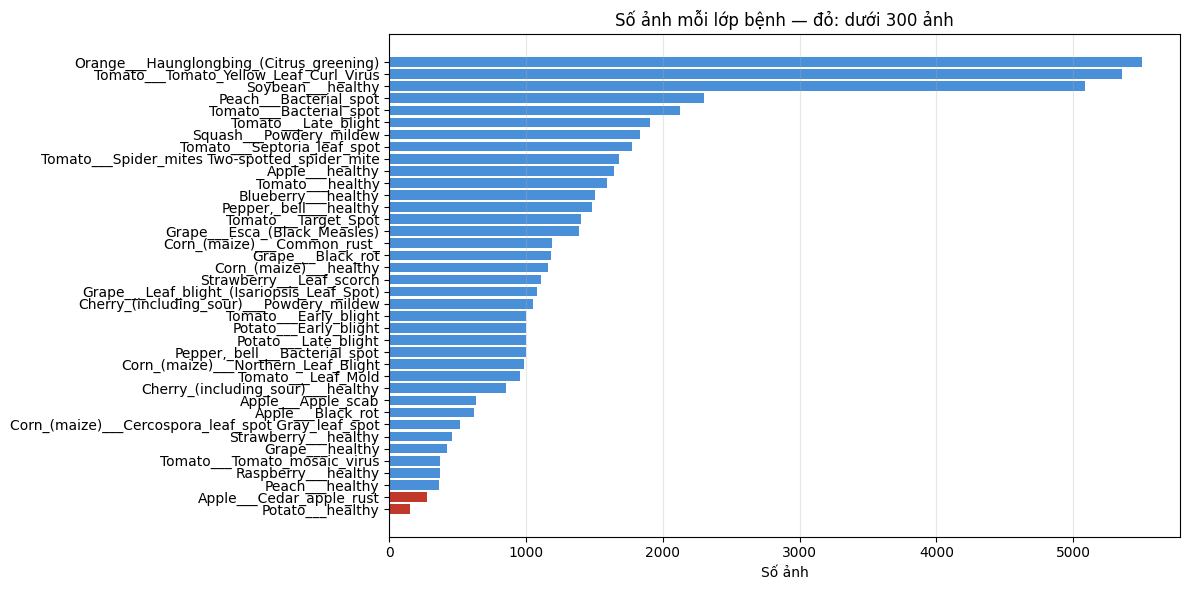

,so_anh,ti_le_%,train_80%,val_10%,test_10%
Orange___Haunglongbing_(Citrus_greening),5507,10.14,4406,551,551
Tomato___Tomato_Yellow_Leaf_Curl_Virus,5357,9.86,4286,536,536
Soybean___healthy,5090,9.37,4072,509,509
Peach___Bacterial_spot,2297,4.23,1838,230,230
Tomato___Bacterial_spot,2127,3.92,1702,213,213
Tomato___Late_blight,1909,3.52,1527,191,191
Squash___Powdery_mildew,1835,3.38,1468,184,184
Tomato___Septoria_leaf_spot,1771,3.26,1417,177,177
Tomato___Spider_mites Two-spotted_spider_mite,1676,3.09,1341,168,168
Apple___healthy,1645,3.03,1316,164,164


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Gom số ảnh của từng lớp bệnh thành bảng để xem mức mất cân bằng
counts = pd.Series(
    {cls: count_images(os.path.join(DATA_DIR, cls))
     for cls in sorted(os.listdir(DATA_DIR))},
    name="so_anh",
).sort_values(ascending=False)

total = int(counts.sum())
dist = pd.DataFrame({
    "so_anh": counts,
    "ti_le_%": (counts / total * 100).round(2),
    # Số ảnh mỗi phía nếu chia 80 / 10 / 10 như mục 5.6
    "train_80%": (counts * 0.80).round().astype(int),
    "val_10%": (counts * 0.10).round().astype(int),
    "test_10%": (counts * 0.10).round().astype(int),
})

print("Tổng số ảnh:", total)
print("Số lớp bệnh:", len(dist))
print("Lớp nhiều nhất:", dist.index[0], "—", int(dist["so_anh"].iloc[0]), "ảnh")
print("Lớp ít nhất  :", dist.index[-1], "—", int(dist["so_anh"].iloc[-1]), "ảnh")
print("Chênh lệch   : %.1f lần" % (dist["so_anh"].iloc[0] / dist["so_anh"].iloc[-1]))

# Tô đỏ các lớp dưới 300 ảnh — đây là những lớp mà 10% validation gần như không đủ dữ liệu để đo
colors = ["#c0392b" if n < 300 else "#4a90d9" for n in dist["so_anh"]]

fig, ax = plt.subplots(figsize=(12, 6))
ax.barh(dist.index[::-1], dist["so_anh"][::-1], color=colors[::-1])
ax.set_xlabel("Số ảnh")
ax.set_title("Số ảnh mỗi lớp bệnh — đỏ: dưới 300 ảnh")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

dist


### 5.4. Trích xuất đặc trưng kèm perceptual hash

Hàm `extract_features` gom 1.977 đặc trưng cho mỗi ảnh. Thêm `perceptual_hash` để tính "vân tay" 64 bit của mỗi ảnh, dùng cho mục 5.5.

`perceptual_hash` dựa trên biến đổi DCT: chuyển ảnh xám về 32×32, lấy khối 8×8 ở góc trên trái — toàn bộ thông tin tần số thấp, tức là hình dạng tổng thể — rồi so từng phần tử với trung bình của khối đó. Hai ảnh cùng một nội dung dù khác nhiễu hay khác độ sáng vẫn cho ra hash gần như giống nhau.

Toàn bộ đặc trưng được cache vào `features.npz`. Colab chỉ có vài nhân, trích xuất hơn 54 nghìn ảnh mất khoảng 15 phút, nên có cache thì những lần chạy sau không phải làm lại.

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from tqdm import tqdm
from skimage.feature import hog

ARTIFACT_DIR = os.path.join(PROJECT_DIR, "artifacts")
FEATURES_PATH = os.path.join(ARTIFACT_DIR, "features.npz")
IMG_SIZE = (128, 128)

os.makedirs(ARTIFACT_DIR, exist_ok=True)


def extract_features(img_seg, img_gray):
    """Trích xuất đặc trưng.

    Dùng ảnh segmented cho đặc trưng màu (loại bỏ nhiễu nền).
    Dùng ảnh grayscale gốc cho cấu trúc và hình học.
    """
    features = []

    # 1. Biểu đồ tần suất màu trong không gian HSV (Dùng ảnh segmented)
    hsv = cv2.cvtColor(img_seg, cv2.COLOR_BGR2HSV)
    for i in range(3):
        hist = cv2.calcHist([hsv], [i], None, [32], [0, 256])
        features.extend(hist.flatten())

    # 2. Biểu đồ tần suất màu trong không gian BGR (Dùng ảnh segmented)
    for i in range(3):
        hist = cv2.calcHist([img_seg], [i], None, [32], [0, 256])
        features.extend(hist.flatten())

    # 3. Đặc trưng HOG, mô tả hình dáng (Dùng ảnh grayscale)
    features.extend(
        hog(img_gray, orientations=9, pixels_per_cell=(16, 16),
            cells_per_block=(2, 2), visualize=False)
    )

    # 4. Thống kê từng kênh màu (Dùng ảnh segmented)
    for ch in list(cv2.split(img_seg)) + list(cv2.split(hsv)):
        features.append(np.mean(ch))
        features.append(np.std(ch))
        features.append(
            float(np.mean((ch - np.mean(ch)) ** 3) / (np.std(ch) ** 3 + 1e-6))
        )

    # 5. Mật độ cạnh (Dùng ảnh grayscale)
    edges = cv2.Canny(img_gray, 50, 150)
    features.append(np.sum(edges) / edges.size)
    features.append(np.mean(edges))
    features.append(np.std(edges))

    return np.array(features, dtype=np.float32)


def perceptual_hash(img_gray):
    """Vân tay 64 bit, tính trên ảnh grayscale."""
    small = cv2.resize(img_gray, (32, 32)).astype(np.float32)
    dct = cv2.dct(small)[:8, :8].flatten()
    med = np.median(dct[1:])
    return int.from_bytes(np.packbits((dct > med).astype(np.uint8)).tobytes(), "big")


def process_image_paths(c_path, g_path, s_path):
    """Đọc các phiên bản ảnh có sẵn trên đĩa."""
    img_seg = cv2.imread(str(s_path))
    img_gray = cv2.imread(str(g_path), cv2.IMREAD_GRAYSCALE)

    if img_seg is None or img_gray is None:
        return None

    img_seg = cv2.resize(img_seg, IMG_SIZE)
    img_gray = cv2.resize(img_gray, IMG_SIZE)

    return extract_features(img_seg, img_gray), perceptual_hash(img_gray)


if os.path.exists(FEATURES_PATH):
    print("Đã có cache đặc trưng — bỏ qua bước trích xuất.")
    cache = np.load(FEATURES_PATH, allow_pickle=True)
    X, phashes, paths, y = cache["X"], cache["phash"], cache["paths"], cache["y"]
else:
    # Gom danh sách ảnh kèm nhãn lớp
    all_c_paths, all_g_paths, all_s_paths, all_labels = [], [], [], []
    n_missing = 0
    for cls in sorted(os.listdir(DATA_DIR_COLOR)):
        cls_color = os.path.join(DATA_DIR_COLOR, cls)
        if not os.path.isdir(cls_color):
            continue

        # Ghép ảnh color với grayscale/segmented qua ánh xạ (không đổi tên file trên đĩa)
        for fname, (g_path, s_path) in build_variant_index(cls).items():
            if g_path is None or s_path is None:
                n_missing += 1
                continue
            all_c_paths.append(os.path.join(cls_color, fname))
            all_g_paths.append(g_path)
            all_s_paths.append(s_path)
            all_labels.append(cls)

    print("Số ảnh thiếu bản grayscale/segmented (bỏ qua):", n_missing)
    print("Số ảnh cần xử lý:", len(all_labels))

    results = Parallel(n_jobs=-1, verbose=1)(
        delayed(process_image_paths)(c, g, s)
        for c, g, s in tqdm(zip(all_c_paths, all_g_paths, all_s_paths), total=len(all_labels))
    )

    # Giữ đúng thứ tự ảnh gốc, bỏ qua những ảnh đọc lỗi
    feats, hashes, kept_paths, kept_labels = [], [], [], []
    for i, (label, res) in enumerate(zip(all_labels, results)):
        if res is None:
            continue
        feat, phash = res
        feats.append(feat)
        hashes.append(phash)
        kept_paths.append(all_c_paths[i])
        kept_labels.append(label)

    if len(feats) == 0:
        raise ValueError("Vẫn không đọc được ảnh nào. Hãy kiểm tra lại file hệ thống.")

    X = np.stack(feats).astype(np.float32)
    phashes = np.array(hashes, dtype=np.uint64)
    paths = np.array(kept_paths)
    y = np.array(kept_labels)

    np.savez_compressed(FEATURES_PATH, X=X, phash=phashes, paths=paths, y=y)
    print("Đã lưu cache:", FEATURES_PATH)

print()
print("Kích thước ma trận đặc trưng:", X.shape)
print("Số ảnh còn lại sau khi bỏ ảnh lỗi:", len(paths))
print("Số giá trị lỗi (NaN hoặc inf):", int(np.sum(~np.isfinite(X))))
print("Số lớp bệnh:", len(np.unique(y)))


Số ảnh thiếu bản grayscale/segmented (bỏ qua): 0
Số ảnh cần xử lý: 54305


100%|██████████| 54305/54305 [00:27<00:00, 1969.06it/s]
[Parallel(n_jobs=-1)]: Done 54024 tasks      | elapsed:   27.9s
[Parallel(n_jobs=-1)]: Done 54305 out of 54305 | elapsed:   27.9s finished


Đã lưu cache: /content/plant-disease/artifacts/features.npz

Kích thước ma trận đặc trưng: (54305, 1977)
Số ảnh còn lại sau khi bỏ ảnh lỗi: 54305
Số giá trị lỗi (NaN hoặc inf): 0
Số lớp bệnh: 38


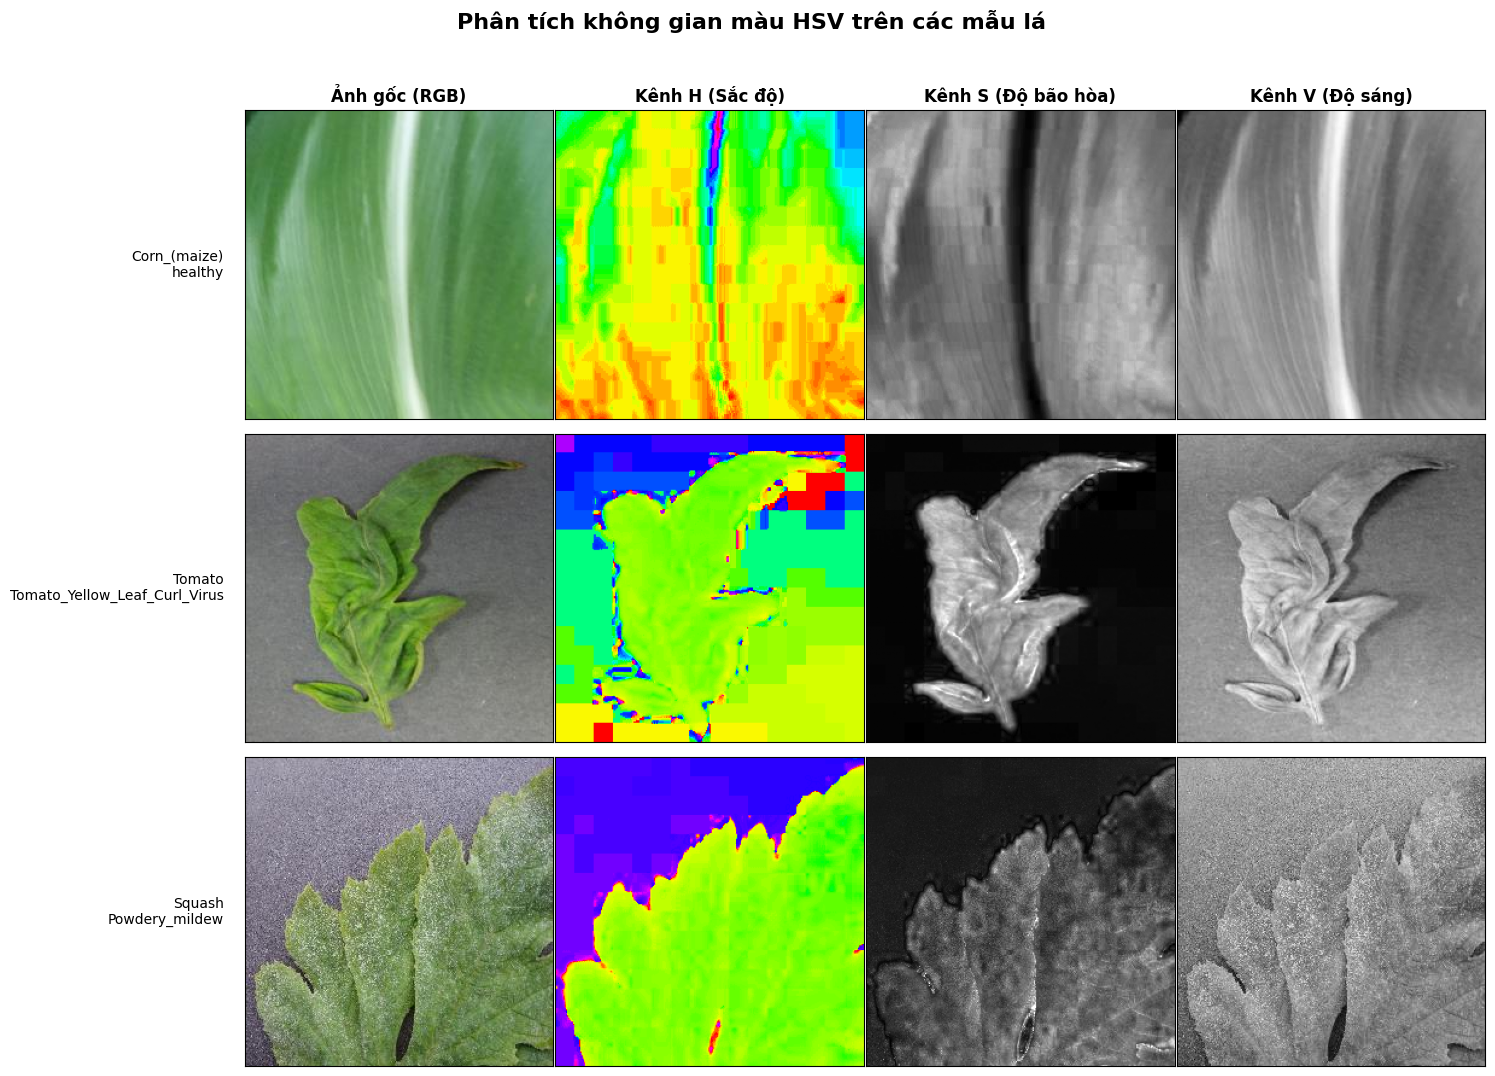

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Chọn 3 mẫu ngẫu nhiên từ các lớp bệnh khác nhau để hiển thị
np.random.seed(42)
sample_indices = np.random.choice(len(paths), 3, replace=False)
CASE_PATHS = [(y[i], paths[i]) for i in sample_indices]

def preprocess(path):
    """Đọc ảnh và chuyển sang không gian màu HSV."""
    img_bgr = cv2.imread(str(path))
    if img_bgr is None:
        return None
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    return {"rgb": img_rgb, "hsv": img_hsv}

fig, axes = plt.subplots(len(CASE_PATHS), 4, figsize=(15, 3.5 * len(CASE_PATHS)))
axes = np.atleast_2d(axes)

# Tiêu đề chuyên nghiệp hơn cho từng cột
caps = ["Ảnh gốc (RGB)", "Kênh H (Sắc độ)",
        "Kênh S (Độ bão hòa)", "Kênh V (Độ sáng)"]

for r, (label, path) in enumerate(CASE_PATHS):
    pre = preprocess(path)
    if pre is None:
        continue
    h, s, v = pre["hsv"][:, :, 0], pre["hsv"][:, :, 1], pre["hsv"][:, :, 2]

    for c, (img, cmap) in enumerate([(pre["rgb"], None), (h, "hsv"),
                                     (s, "gray"), (v, "gray")]):
        axes[r, c].imshow(img, cmap=cmap)
        axes[r, c].set_xticks([])
        axes[r, c].set_yticks([])
        if r == 0:
            axes[r, c].set_title(caps[c], fontsize=12, fontweight="bold")

    # Hiển thị tên lớp bệnh ở cột đầu tiên, chia dòng cho dễ đọc
    axes[r, 0].set_ylabel(label.replace("___", "\n"), fontsize=10, rotation=0, ha="right", va="center", labelpad=15)

# Tiêu đề tổng quát chuyên nghiệp
fig.suptitle('Phân tích không gian màu HSV trên các mẫu lá', fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

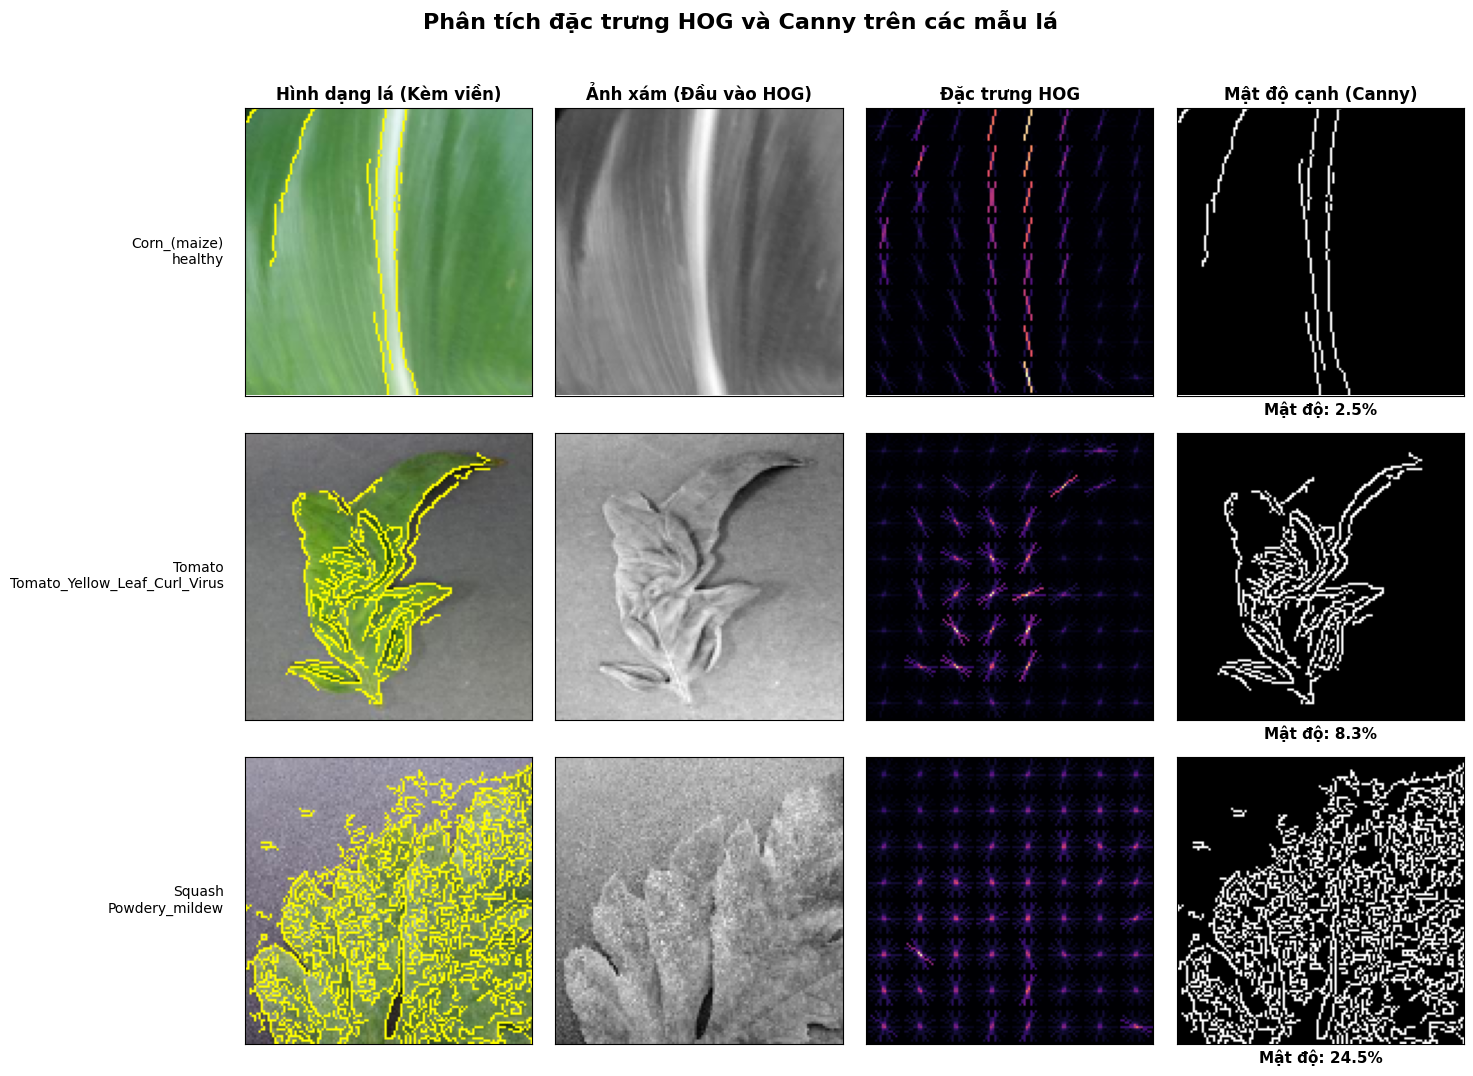

In [ ]:
from skimage.feature import hog

fig, axes = plt.subplots(len(CASE_PATHS), 4, figsize=(15, 3.5 * len(CASE_PATHS)))
axes = np.atleast_2d(axes)

# Các tiêu đề chuyên nghiệp
caps = ["Hình dạng lá (Kèm viền)", "Ảnh xám (Đầu vào HOG)",
        "Đặc trưng HOG", "Mật độ cạnh (Canny)"]

for r, (label, path) in enumerate(CASE_PATHS):
    img_bgr = cv2.imread(str(path))
    if img_bgr is None: continue

    # Resize về 128x128 để khớp với bước trích xuất đặc trưng
    img_bgr = cv2.resize(img_bgr, (128, 128))
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    # Trích xuất HOG (Khớp với tham số ở mục 5.4)
    _, hog_img = hog(gray, orientations=9, pixels_per_cell=(16, 16),
                     cells_per_block=(2, 2), visualize=True)

    # Canny và mật độ cạnh
    edges = cv2.Canny(gray, 50, 150)
    density = np.count_nonzero(edges) / edges.size * 100

    # Tạo ảnh viền lá màu vàng (Overlay)
    outline_img = img_rgb.copy()
    outline_img[edges > 0] = [255, 255, 0]  # Viền vàng

    panels = [
        (outline_img, None),
        (gray, "gray"),
        (hog_img, "magma"), # Thêm màu magma để nhìn HOG rõ hơn
        (edges, "gray"),
    ]

    for c, (img, cmap) in enumerate(panels):
        axes[r, c].imshow(img, cmap=cmap)
        axes[r, c].set_xticks([])
        axes[r, c].set_yticks([])
        if r == 0:
            axes[r, c].set_title(caps[c], fontsize=12, fontweight="bold")

    axes[r, 3].set_xlabel(f"Mật độ: {density:.1f}%", fontsize=11, fontweight="bold")
    axes[r, 0].set_ylabel(label.replace("___", "\n"), fontsize=10, rotation=0, ha="right", va="center", labelpad=15)

fig.suptitle('Phân tích đặc trưng HOG và Canny trên các mẫu lá', fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

### 5.5. Dựng nhóm ảnh trùng lặp

Dữ liệu PlantVillage được chụp theo cụm: nhiều ảnh của **cùng một chiếc lá**, cùng nền, cùng góc máy. Bản cũ chia tập ngẫu nhiên ở mức từng ảnh, nên ảnh gần trùng của một lá có thể rơi vào cả train và test. Mô hình khi đó không học "hình dạng đốm bệnh" mà học "chiếc lá này trông thế nào" — đó là rò rỉ dữ liệu ở mức phương pháp.

Cách sửa: gom các ảnh gần trùng thành một **nhóm**, rồi chia tập theo nhóm thay vì theo ảnh. Khi đó một chiếc lá luôn nằm trọn vẹn ở một phía.

Vì tận dữ liệu không có mã cây, ta tự dò bằng khoảng cách Hamming giữa các perceptual hash, rồi dùng Union-Find để gom các ảnh liên kết thành cùng một nhóm. Chỉ so trong cùng lớp bệnh — ảnh khác lớp không thể trùng nhau, và cách này nhanh hơn nhiều.


In [ ]:
def popcount(x):
    """Đếm số bit 1 trong từng phần tử, tương thích cả numpy 1.x và 2.x."""
    if hasattr(np, "bitwise_count"):
        return np.bitwise_count(x)

    # Cách dự phòng cho numpy 1.x: dùng phép trừ có mượn, loại bỏ từng cặp bit một lượt
    x = x - ((x >> np.uint64(1)) & np.uint64(0x5555555555555555))
    x = (x & np.uint64(0x3333333333333333)) + ((x >> np.uint64(2)) & np.uint64(0x3333333333333333))
    x = (x + (x >> np.uint64(4))) & np.uint64(0x0F0F0F0F0F0F0F0F)
    return ((x * np.uint64(0x0101010101010101)) >> np.uint64(56)).astype(np.uint8)


class UnionFind:
    """Gom phần tử thành nhóm bằng đường dẫn nén, gần như O(1) mỗi thao tác."""

    def __init__(self, n):
        self.parent = np.arange(n)

    def find(self, a):
        root = a
        while self.parent[root] != root:
            root = self.parent[root]

        while self.parent[a] != root:          # nén đường dẫn
            self.parent[a], a = root, self.parent[a]

        return root

    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra != rb:
            self.parent[max(ra, rb)] = min(ra, rb)


MAX_HAMMING = 12     # chỉ ghi lại các cặp gần trùng, không lưu toàn bộ khoảng cách
near_pairs = []      # mỗi phần tử là (chỉ số ảnh 1, chỉ số ảnh 2, khoảng cách Hamming)

# Quét từng lớp bệnh, chia thành lô nhỏ để không dồn toàn bộ ma trận khoảng cách vào bộ nhớ
for cls in sorted(np.unique(y)):
    idx = np.flatnonzero(y == cls)
    hashes = phashes[idx]
    n = len(hashes)

    for start in range(0, n, 512):
        block = hashes[start:start + 512, None]
        dist = popcount(block ^ hashes[None, :])

        r, c = np.nonzero(np.asarray(dist) <= MAX_HAMMING)
        keep = (r + start) < c                 # mỗi cặp chỉ giữ một lần
        for rr, cc in zip(r[keep], c[keep]):
            near_pairs.append((int(idx[start + rr]), int(idx[cc]), int(dist[rr, cc])))

print("Số cặp ảnh gần trùng tìm được (khoảng cách <= %d):" % MAX_HAMMING, len(near_pairs))

Số cặp ảnh gần trùng tìm được (khoảng cách <= 12): 267561


In [ ]:
groups_path = os.path.join(ARTIFACT_DIR, "groups.csv")
HAMMING_THRESHOLD = 4    # ngưỡng chốt, xem bảng thống kê bên dưới để biết lý do chọn

# Nạp lại nhóm từ lần chạy trước nếu còn khớp, khỏi quét lại toàn bộ khoảng cách Hamming
groups = None
if os.path.exists(groups_path):
    cached = pd.read_csv(groups_path)
    if len(cached) == len(y):
        groups = cached["group"].to_numpy()
        print("Đã nạp lại nhóm từ cache:", groups_path)


def build_groups(threshold):
    """Gán group_id cho mỗi ảnh: các ảnh gần trùng nhau nằm chung một nhóm."""
    uf = UnionFind(len(y))

    for i, j, dist in near_pairs:
        if dist <= threshold:
            uf.union(i, j)

    return np.array([uf.find(k) for k in range(len(y))])


if groups is None:
    # Chọn ngưỡng dựa trên số liệu thay vì đặt tùy tiện: ngưỡng càng cao thì càng
    # nhiều ảnh bị gom chung, cho tới khi ảnh của những chiếc lá khác bắt đầu bị gom nhầm.
    print("%-10s %-12s %-26s %-16s" % ("Ngưỡng", "Số nhóm", "Ảnh ở nhóm >1 ảnh", "Nhóm lớn nhất"))
    print("-" * 70)

    for th in [0, 2, 4, 6, 8, 10, 12]:
        g = build_groups(th)
        s = pd.Series(g).value_counts()
        print("%-10d %-12d %-26d %-16d"
              % (th, len(s), int(s[s > 1].sum()), int(s.iloc[0])))

    groups = build_groups(HAMMING_THRESHOLD)

    pd.DataFrame({"path": paths, "label": y, "group": groups}).to_csv(
        groups_path, index=False)
    print("\nĐã lưu:", groups_path)

sizes = pd.Series(groups).value_counts()

print("\nNgưỡng Hamming dùng chốt:", HAMMING_THRESHOLD)
print("Tổng số nhóm:", len(sizes))
print("Ảnh nằm trong nhóm có từ 2 ảnh trở lên:", int(sizes[sizes > 1].sum()))
print("Ảnh nằm trong nhóm có từ 3 ảnh trở lên:", int(sizes[sizes >= 3].sum()))
print("Nhóm lớn nhất gồm", int(sizes.iloc[0]), "ảnh")

Ngưỡng     Số nhóm      Ảnh ở nhóm >1 ảnh          Nhóm lớn nhất   
----------------------------------------------------------------------
0          54281        48                         2               
2          54206        191                        5               
4          53393        1317                       151             
6          51001        4178                       2056            
8          46551        9515                       3738            
10         37954        18749                      4591            
12         25647        30721                      4932            

Đã lưu: /content/plant-disease/artifacts/groups.csv

Ngưỡng Hamming dùng chốt: 4
Tổng số nhóm: 53393
Ảnh nằm trong nhóm có từ 2 ảnh trở lên: 1317
Ảnh nằm trong nhóm có từ 3 ảnh trở lên: 703
Nhóm lớn nhất gồm 151 ảnh


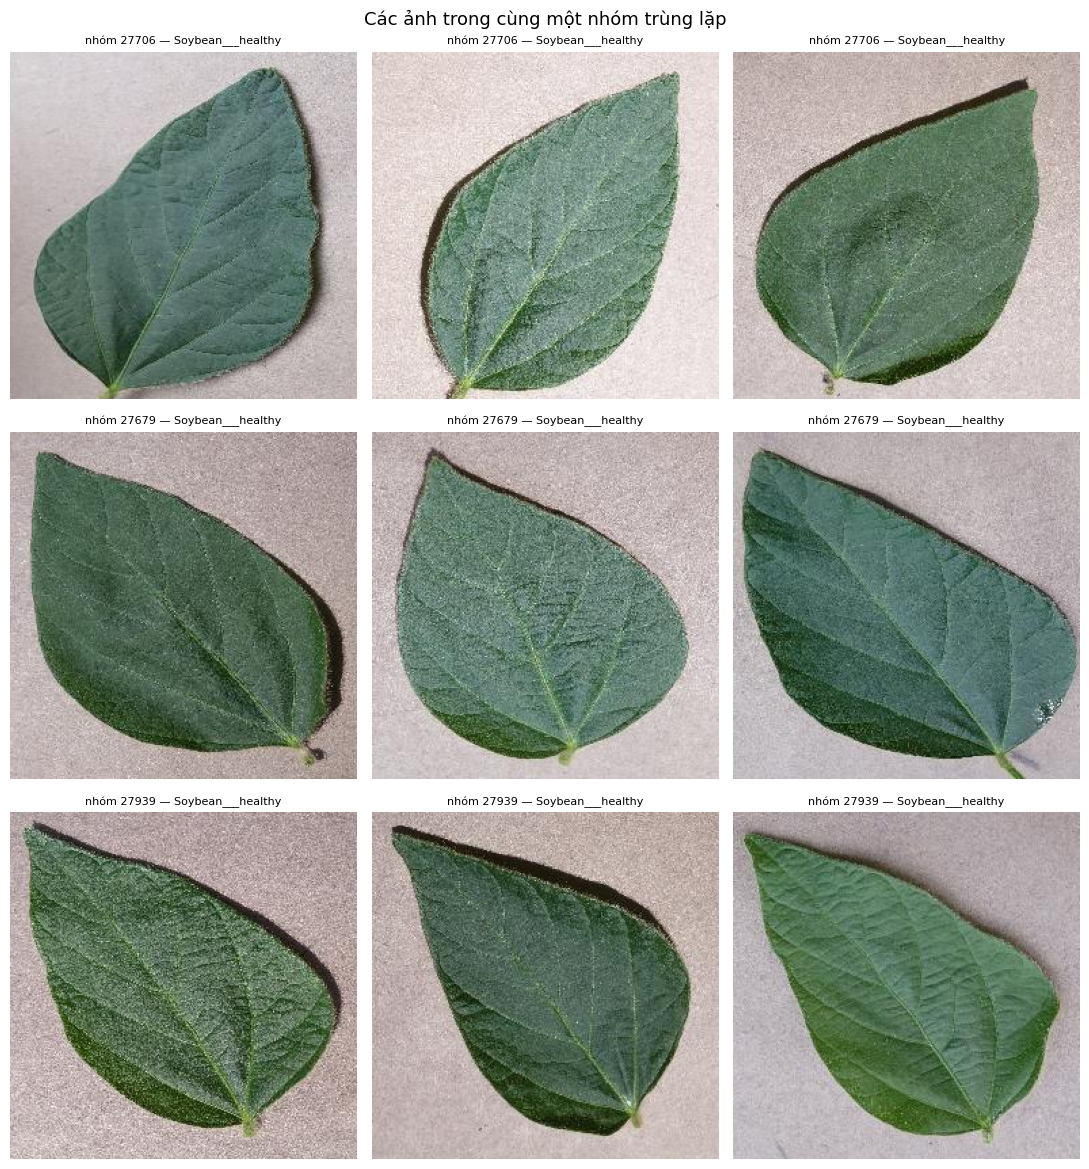

In [ ]:
# Xem vài cụm ảnh gần trùng: nếu các ảnh trong một cụm thực sự là cùng một chiếc lá được
# chụp nhiều lần, thì đây chính là bằng chứng cho thấy chia tập ở mức ảnh là không đúng.
cluster_sizes = pd.Series(groups).value_counts()
big_clusters = cluster_sizes[cluster_sizes >= 3].index.tolist()[:3]

fig, axes = plt.subplots(len(big_clusters), 3, figsize=(11, 4 * len(big_clusters)))
axes = np.atleast_2d(axes)

for r, gid in enumerate(big_clusters):
    members = np.flatnonzero(groups == gid)[:3]
    for c, m in enumerate(members):
        img = cv2.imread(str(paths[m]))
        axes[r, c].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        axes[r, c].set_title("nhóm %d — %s" % (gid, y[m][:28]), fontsize=8)
        axes[r, c].axis("off")

plt.suptitle("Các ảnh trong cùng một nhóm trùng lặp", fontsize=13)
plt.tight_layout()
plt.show()

### 5.6. Chia tập dữ liệu

Chia theo **nhóm ảnh**, không theo từng ảnh: mọi ảnh của cùng một chiếc lá luôn nằm trọn vẹn ở một phía. Tỉ lệ 80% train / 10% validation / 10% test.

`train_test_split` không nhận tham số `groups`, nên hàm bên dưới dùng `StratifiedGroupKFold` với số fold bằng `1 / test_size` rồi lấy một fold làm tập kiểm tra. Với tỉ lệ 10% thì số fold là 10, ra đúng tỉ lệ mong muốn.

Về câu hỏi thường gặp: **trích xuất đặc trưng trước rồi mới chia tập có phải rò rỉ không?** Không phải.

Rò rỉ chỉ xảy ra khi một bước học thống kê nào đó — chuẩn hoá đặc trưng, PCA, cắt chọn đặc trưng — được *fit* trên toàn bộ tập dữ liệu rồi mới chia. Ở đây `extract_features` biến đổi từng ảnh một cách hoàn toàn độc lập, không có thống kê nào đi xuyên suốt tập ảnh, nên trích xuất trước hay sau khi chia đều cho cùng một kết quả. Vấn đề thật nằm ở chỗ khác: **cách chia ở mức từng ảnh**, đã nêu ở mục 5.5.

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

# Mã hoá nhãn lớp bệnh thành số nguyên 0..37
CLASSES = sorted(np.unique(y))
class_to_idx = {name: i for i, name in enumerate(CLASSES)}
y_enc = np.array([class_to_idx[label] for label in y], dtype=np.int32)

all_idx = np.arange(len(y_enc))


def split_by_group(idx, labels, test_size):
    """Chia tập theo nhóm ảnh, đồng thời giữ tỉ lệ các lớp bệnh.

    `train_test_split` không nhận tham số `groups`, nên ở đây dùng
    `StratifiedGroupKFold` với số fold bằng `1 / test_size` rồi lấy một fold
    làm tập kiểm tra.
    """
    n_splits = round(1 / test_size)

    # Thử nhiều seed khác nhau, phòng khi một lớp quá hiếm rơi hẳn vào một fold
    for seed in (42, 7, 13, 2024, 99):
        splitter = StratifiedGroupKFold(n_splits=n_splits, shuffle=True,
                                        random_state=seed)
        train_idx, test_idx = next(iter(splitter.split(idx, labels, groups[idx])))

        if len(np.unique(labels[test_idx])) == len(np.unique(labels)):
            return idx[train_idx], idx[test_idx]

    raise RuntimeError(
        "Không chia được tập theo nhóm mà vẫn giữ đủ các lớp. "
        "Có lớp quá ít ảnh so với số fold."
    )


# 80% train
train_idx, rest = split_by_group(all_idx, y_enc, test_size=0.20)

# Tách tiếp 10% validation và 10% test từ 20% còn lại
val_idx, test_idx = split_by_group(rest, y_enc[rest], test_size=0.50)

# 90% dùng cho tìm siêu tham số, không bao giờ chạm vào test
cv_idx = np.concatenate([train_idx, val_idx])

print("train %6d | val %6d | test %6d   (tổng %d ảnh)"
      % (len(train_idx), len(val_idx), len(test_idx), len(y)))
print("Số lớp bệnh:", len(CLASSES))
print("Tổng số nhóm ảnh trùng lặp:", len(np.unique(groups)))

train  43238 | val   5399 | test   5668   (tổng 54305 ảnh)
Số lớp bệnh: 38
Tổng số nhóm ảnh trùng lặp: 53393


### 5.7. Kiểm tra tính đúng đắn của cách chia

Dễ làm sai mà không biết, nên cần phép kiểm tra bằng code chứ không tin bằng mắt. Điều kiện cần đạt: **không nhóm ảnh nào được xuất hiện ở cả hai phía**.

In [ ]:
def check_group_leak(name, left_idx, right_idx, right_label):
    """Báo xem có nhóm ảnh nào nằm ở cả hai tập hay không."""
    left_groups = set(groups[left_idx].tolist())
    right_groups = set(groups[right_idx].tolist())
    shared = left_groups & right_groups

    if shared:
        print("  [%s] RÒ RỈ: %d nhóm nằm ở cả train và %s" % (name, len(shared), right_label))
        for g in sorted(shared)[:3]:
            print("     ví dụ nhóm %d — gồm %d ảnh" % (g, int((groups == g).sum())))
    else:
        print("  [%s] SẠCH — không nhóm nào chung giữa train và %s" % (name, right_label))

    return len(shared)


print("Kiểm tra cách chia 80/10/10 theo nhóm:")
check_group_leak("train", train_idx, val_idx, "validation")
check_group_leak("train", train_idx, test_idx, "test")
check_group_leak("train+val", cv_idx, test_idx, "test")

print("\nSố lớp bệnh xuất hiện ở từng tập:")
for label, idx in [("train", train_idx), ("validation", val_idx), ("test", test_idx)]:
    print("  %-11s: %d / %d lớp" % (label, len(np.unique(y_enc[idx])), len(CLASSES)))

print("\nKỳ vọng: cả ba dòng kiểm tra đều SẠCH.")

Kiểm tra cách chia 80/10/10 theo nhóm:
  [train] SẠCH — không nhóm nào chung giữa train và validation
  [train] SẠCH — không nhóm nào chung giữa train và test
  [train+val] SẠCH — không nhóm nào chung giữa train và test

Số lớp bệnh xuất hiện ở từng tập:
  train      : 38 / 38 lớp
  validation : 38 / 38 lớp
  test       : 38 / 38 lớp

Kỳ vọng: cả ba dòng kiểm tra đều SẠCH.


## 6. Huấn luyện mô hình Random Forest

Mô hình được huấn luyện trên bộ đặc trưng hình học truyền thống, không dùng mạng neuron sâu.

### 6.1. Kiểm tra tổng số ảnh và số lớp

Tổng hợp số ảnh và số lớp bạn sẽ dùng để huấn luyện.

In [ ]:
# Tính tổng số ảnh của tất cả các lớp
total_images = sum(
    count_images(os.path.join(DATA_DIR, cls))
    for cls in os.listdir(DATA_DIR)
    if os.path.isdir(os.path.join(DATA_DIR, cls))
)

print("Tổng số ảnh:", total_images)
print("Tổng số lớp:", len(class_dirs))


Tổng số ảnh: 54305
Tổng số lớp: 38


### 6.2. Kiểm tra thư mục lưu mô hình

Khai báo sẵn đường dẫn hai file mô hình để mục 6.5 lưu vào, đồng thời xem chúng đã tồn tại chưa. Nếu file đã có từ lần chạy trước thì kết quả ở 6.3 và 6.6 vẫn nên chạy lại, vì các phép so sánh ở đó phụ thuộc vào cách chia tập chứ không phụ thuộc vào mô hình đã lưu.


In [ ]:
import os

# Thư mục lưu mô hình, nằm trong thư mục làm việc đã tạo ở mục 1
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
MODEL_PATH = os.path.join(MODEL_DIR, "random_forest_model.pkl")
ENCODER_PATH = os.path.join(MODEL_DIR, "label_encoder.pkl")

# True khi cả hai file đều tồn tại và không rỗng, tức là mô hình đã được huấn luyện xong
MODEL_EXISTS = all(
    os.path.exists(p) and os.path.getsize(p) > 0
    for p in (MODEL_PATH, ENCODER_PATH)
)

print("random_forest_model.pkl ->", os.path.exists(MODEL_PATH))
print("label_encoder.pkl       ->", os.path.exists(ENCODER_PATH))

random_forest_model.pkl -> False
label_encoder.pkl       -> False


In [ ]:
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

# ------------------------------------------------------------------
# Cấu hình tham số và không gian tìm kiếm
# ------------------------------------------------------------------
SEED = 42
N_SPLITS = 5

SEARCH_FRAC = 0.30     # Tỉ lệ ảnh dùng khi tìm kiếm thô (mỗi fold)
N_TREES_SEARCH = 80    # Số cây khi tìm kiếm thô ở tầng 1
N_TREES_CHECK = 150    # Số cây khi kiểm chứng ở tầng 2
N_TREES_FINAL = 300    # Số cây tối đa

N_TRIALS = 40          # Số cấu hình ngẫu nhiên thử ở tầng 1
N_TOP = 5              # Số cấu hình tốt nhất đưa lên tầng 2
N_REPEATS = 2          # Tần số lặp

# Khởi tạo ma trận và dữ liệu
Xc = np.ascontiguousarray(X, dtype=np.float32) if 'X' in globals() else None
yc = y_enc if 'y_enc' in globals() else None
gc = groups if 'groups' in globals() else None

# Không gian tìm kiếm tham số
SEARCH_SPACE = {
    "max_depth": [None, 12, 20, 30, 45],
    "min_samples_split": [2, 4, 8, 16, 32],
    "min_samples_leaf": [1, 2, 4, 8, 16],
    "max_features": ["sqrt", "log2", 0.05, 0.1, 0.2, 0.3, 0.5],
    "criterion": ["gini", "entropy", "log_loss"],
    "class_weight": [None, "balanced", "balanced_subsample"],
    "max_samples": [0.6, 0.8, 1.0],
    "min_weight_fraction_leaf": [0.0, 0.01, 0.05],
    "ccp_alpha": [0.0, 0.001, 0.01, 0.05],
}

try:
    RandomForestClassifier(criterion="log_loss", n_estimators=1).fit(np.zeros((10, 2)), np.zeros(10))
except Exception:
    SEARCH_SPACE["criterion"] = ["gini", "entropy"]
    print("sklearn cũ - Đã loại bỏ 'log_loss'")

def make_model(params, n_trees):
    return RandomForestClassifier(
        n_estimators=n_trees,
        n_jobs=-1,
        random_state=SEED,
        **params
    )

def subsample_fold(train_f, val_f, frac=1.0):
    """Lấy mẫu ngẫu nhiên một phần dữ liệu train của fold để tăng tốc độ tìm kiếm."""
    if frac >= 1.0:
        return train_f, val_f
    rng = np.random.default_rng(SEED)
    train_sub = rng.choice(train_f, int(len(train_f) * frac), replace=False)
    return train_sub, val_f

def eval_config(params, folds_, n_trees, frac=1.0):
    scores = []
    for tr, va in folds_:
        tr2, va2 = subsample_fold(tr, va, frac)
        model = make_model(params, n_trees)
        model.fit(Xc[tr2], yc[tr2])
        scores.append(f1_score(yc[va2], model.predict(Xc[va2]), average="macro"))
    return float(np.mean(scores)), float(np.std(scores)), scores

def evaluate(params, folds_, frac=1.0, n_trees=N_TREES_FINAL):
    """Hàm đánh giá nhanh cấu hình trả về (mean, std) dùng cho Tầng 3 và Validation."""
    mean_score, std_score, _ = eval_config(params, folds_, n_trees, frac=frac)
    return mean_score, std_score


def complexity(params):
    depth = params.get("max_depth")
    depth = 999 if depth is None else depth
    mf = params.get("max_features", "sqrt")
    if mf == "sqrt":
        mf_n = 44
    elif mf == "log2":
        mf_n = 11
    else:
        mf_n = float(mf) * Xc.shape[1] if Xc is not None else 44
    return (depth, mf_n, params.get("min_samples_leaf", 1))

print("Đã khôi phục và định nghĩa đầy đủ các biến cấu hình, subsample_fold và evaluate!")

Đã khôi phục và định nghĩa đầy đủ các biến cấu hình, subsample_fold và evaluate!


### 6.3. Tìm siêu tham số bằng 5-fold

`RandomizedSearchCV` chạy trên **90% (train + validation)**, không đụng vào tập test 10%.

Chấm bằng `f1_macro` chứ không phải `accuracy`: dữ liệu mất cân bằng 36 lần, nên một mô hình cứ dự đoán vào các lớp đông ảnh vẫn đạt accuracy cao mà bỏ qua hẳn các lớp hiếm. Với bài toán nhận diện bệnh, bỏ sót lớp hiếm thì mô hình vô dụng đúng ở chỗ cần đến nhất — nên phải nhìn `macro-F1`, là chỉ số coi mọi lớp ngang nhau.

Kết quả báo cáo dạng mean ± std của cả 5 fold, không phải một điểm đơn.


In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

# Khởi tạo bộ chia fold StratifiedGroupKFold với N_SPLITS = 5
sgkf = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

# Tạo danh sách các fold trên tập dữ liệu cv_idx (train + val)
folds = list(sgkf.split(cv_idx, y_enc[cv_idx], groups=groups[cv_idx]))

# Kiểm tra số lượng ảnh trong mỗi fold
for fold_idx, (train_f, val_f) in enumerate(folds):
    print(f"Fold {fold_idx + 1}: Train = {len(train_f)} ảnh, Val = {len(val_f)} ảnh")

Fold 1: Train = 38880 ảnh, Val = 9757 ảnh
Fold 2: Train = 38933 ảnh, Val = 9704 ảnh
Fold 3: Train = 38912 ảnh, Val = 9725 ảnh
Fold 4: Train = 38891 ảnh, Val = 9746 ảnh
Fold 5: Train = 38932 ảnh, Val = 9705 ảnh


### Tầng 1: Tìm kiếm thô (Stage 1)
Dưới đây là quá trình tìm kiếm thô với `ParameterSampler` chạy trên một phần dữ liệu (`SEARCH_FRAC = 30%`) và số cây nhỏ (`N_TREES_SEARCH = 80`) để lọc ra các cấu hình tiềm năng nhất.

In [ ]:
import time
import numpy as np
import pandas as pd
from tqdm.notebook import tqdm
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, ParameterSampler
from sklearn.metrics import f1_score

t0 = time.time()
# Khởi tạo bộ lấy mẫu ngẫu nhiên không gian tham số
param_list = list(ParameterSampler(SEARCH_SPACE, n_iter=N_TRIALS, random_state=SEED))

stage1_rows = []
print(f"Tầng 1: Thử nghiệm {N_TRIALS} cấu hình trên {int(SEARCH_FRAC * 100)}% dữ liệu...")

for config_idx, params in enumerate(tqdm(param_list, desc="Cấu hình tham số")):
    fold_scores, fit_times = [], []
    rng = np.random.default_rng(SEED + config_idx)

    for fold_idx, (train_f, val_f) in enumerate(tqdm(folds, desc=f"Cấu hình {config_idx+1} - Folds", leave=False)):
        train_sub = rng.choice(train_f, int(len(train_f) * SEARCH_FRAC), replace=False)
        X_train_f, y_train_f = Xc[train_sub], yc[train_sub]
        X_val_f, y_val_f = Xc[val_f], yc[val_f]

        clf = make_model(params, N_TREES_SEARCH)
        start_time = time.time()
        clf.fit(X_train_f, y_train_f)
        fit_times.append(time.time() - start_time)

        preds = clf.predict(X_val_f)
        fold_scores.append(f1_score(y_val_f, preds, average="macro"))

    res_row = {
        "mean_test_score": float(np.mean(fold_scores)),
        "std_test_score": float(np.std(fold_scores)),
        "mean_fit_time": float(np.mean(fit_times)),
    }
    for k, v in params.items():
        res_row[f"param_{k}"] = v
    stage1_rows.append(res_row)

stage1 = pd.DataFrame(stage1_rows).sort_values("mean_test_score", ascending=False)
print("\n--- 5 cấu hình tốt nhất ở tầng 1 ---")
display(stage1.head(5).round(4))
print("Thời gian tầng 1: %.1f phút" % ((time.time() - t0) / 60))

Tầng 1: Thử nghiệm 40 cấu hình trên 30% dữ liệu...


Cấu hình tham số:   0%|          | 0/40 [00:00<?, ?it/s]

Cấu hình 1 - Folds:   0%|          | 0/5 [00:00<?, ?it/s]

Cấu hình 2 - Folds:   0%|          | 0/5 [00:00<?, ?it/s]

Cấu hình 3 - Folds:   0%|          | 0/5 [00:00<?, ?it/s]

Cấu hình 4 - Folds:   0%|          | 0/5 [00:00<?, ?it/s]

... (35 outputs left out)

Cấu hình 40 - Folds:   0%|          | 0/5 [00:00<?, ?it/s]


--- 5 cấu hình tốt nhất ở tầng 1 ---


,mean_test_score,std_test_score,mean_fit_time,param_min_weight_fraction_leaf,param_min_samples_split,param_min_samples_leaf,param_max_samples,param_max_features,param_max_depth,param_criterion,param_class_weight,param_ccp_alpha
31,0.7730,0.0039,13.8037,0.0,8,1,1.0,0.1,20.0,entropy,balanced_subsample,0.001
39,0.7694,0.0065,63.5962,0.0,16,2,1.0,0.5,45.0,log_loss,balanced_subsample,0.001
29,0.7175,0.0106,10.7207,0.0,2,4,0.8,0.2,30.0,gini,balanced_subsample,0.001
9,0.7146,0.0041,12.5171,0.0,4,8,1.0,0.1,NaN,log_loss,None,0.001
32,0.7145,0.0044,24.6470,0.0,16,8,0.6,0.3,30.0,entropy,None,0.001


Thời gian tầng 1: 37.2 phút


### Tầng 2: Kiểm chứng Top-5 (Stage 2)

Đánh giá lại top 5 cấu hình tốt nhất từ tầng 1 trên toàn bộ dữ liệu huấn luyện (`frac=1.0`) và tăng số lượng cây lên `N_TREES_CHECK = 150` cây.

In [ ]:
t1 = time.time()
top_configs = stage1.head(N_TOP).to_dict("records")
stage2_rows = []

print("Tầng 2: Kiểm chứng top-5 trên toàn bộ dữ liệu...")
for i, row in enumerate(top_configs, 1):
    params = {k[len("param_"):]: row[k] for k in stage1.columns if k.startswith("param_")}

    # Sửa lỗi Pandas ép kiểu int thành float khi có chứa giá trị None/NaN
    for int_param in ["max_depth", "min_samples_split", "min_samples_leaf"]:
        if int_param in params:
            if pd.isna(params[int_param]):
                params[int_param] = None
            else:
                params[int_param] = int(params[int_param])

    mean, std, _ = eval_config(params, folds, N_TREES_CHECK, frac=1.0)

    out = {"mean_test_score": mean, "std_test_score": std}
    out.update(params)
    stage2_rows.append(out)
    print("  [%d/%d] macro-F1 = %.4f ± %.4f" % (i, N_TOP, mean, std))

stage2 = pd.DataFrame(stage2_rows).sort_values("mean_test_score", ascending=False)
print("\n--- Kết quả tầng 2 (100%% dữ liệu, %d cây) ---" % N_TREES_CHECK)
display(stage2.round(4))
print("Thời gian tầng 2: %.1f phút" % ((time.time() - t1) / 60))

Tầng 2: Kiểm chứng top-5 trên toàn bộ dữ liệu...
  [1/5] macro-F1 = 0.7897 ± 0.0071
  [2/5] macro-F1 = 0.7897 ± 0.0060
  [3/5] macro-F1 = 0.6732 ± 0.0068
  [4/5] macro-F1 = 0.7643 ± 0.0046
  [5/5] macro-F1 = 0.7837 ± 0.0055

--- Kết quả tầng 2 (100% dữ liệu, 150 cây) ---


,mean_test_score,std_test_score,min_weight_fraction_leaf,min_samples_split,min_samples_leaf,max_samples,max_features,max_depth,criterion,class_weight,ccp_alpha
0,0.7897,0.0071,0.0,8,1,1.0,0.1,20.0,entropy,balanced_subsample,0.001
1,0.7897,0.0060,0.0,16,2,1.0,0.5,45.0,log_loss,balanced_subsample,0.001
4,0.7837,0.0055,0.0,16,8,0.6,0.3,30.0,entropy,None,0.001
3,0.7643,0.0046,0.0,4,8,1.0,0.1,NaN,log_loss,None,0.001
2,0.6732,0.0068,0.0,2,4,0.8,0.2,30.0,gini,balanced_subsample,0.001


Thời gian tầng 2: 78.6 phút


### Tầng 3: Tinh chỉnh cục bộ & Chốt kết quả (Stage 3)
Tại đây chúng ta sẽ thực hiện chọn lọc cấu hình đơn giản hóa trong vùng tương đương hiệu năng (phá thế hòa bằng độ phức tạp), sau đó tiến hành tinh chỉnh cục bộ từng tham số đơn lẻ.

In [ ]:
t2 = time.time()

# Khắc phục lỗi ép kiểu float/NaN từ pandas cho toàn bộ bảng stage2 trước khi xử lý
for col in ["max_depth", "min_samples_split", "min_samples_leaf"]:
    if col in stage2.columns:
        stage2[col] = stage2[col].apply(lambda x: None if pd.isna(x) else int(x))

# Find the simplest configuration within equivalent range (difference less than 1 std)
best_mean = stage2["mean_test_score"].iloc[0]
cutoff = best_mean - stage2["std_test_score"].iloc[0]
plateau = stage2[stage2["mean_test_score"] >= cutoff].copy()

plateau["complexity_score"] = plateau.apply(
    lambda r: complexity({k: r[k] for k in SEARCH_SPACE if k in r}), axis=1
)
chosen_row = plateau.sort_values(["complexity_score", "mean_test_score"], ascending=[True, False]).iloc[0]

current = {k: chosen_row[k] for k in SEARCH_SPACE if k in chosen_row}
current_params = dict(current)

print("Stage 3: Local fine-tuning starting from the selected configuration...")
print("Starting point: %.4f" % best_mean)

variants = {
    "max_depth": [None, 15, 20],
    "min_samples_split": [2, 4, 8, 16],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": ["sqrt", "log2", 0.1, 0.2],
    "class_weight": [None, "balanced", "balanced_subsample"],
}

best_local_score = best_mean
for name, options in variants.items():
    for value in options:
        if value == current_params.get(name):
            continue
        trial_params = dict(current_params)
        trial_params[name] = value
        mean_score, _ = evaluate(trial_params, folds, frac=SEARCH_FRAC)
        flag = ""
        if mean_score > best_local_score:
            best_local_score = mean_score
            current_params = trial_params
            flag = "   <-- updated optimal configuration"
        print("   %-26s = %-18s macro-F1 = %.4f%s" % (name, str(value), mean_score, flag))

# Evaluate final configuration on 100% of training data
refined_mean, refined_std = evaluate(current_params, folds, frac=1.0)
print("\nConfiguration after local fine-tuning on 100%% train: %.4f ± %.4f" % (refined_mean, refined_std))

if refined_mean >= chosen_row["mean_test_score"]:
    best_params = dict(current_params)
    final_mean, final_std = refined_mean, refined_std
    final_source = "after local fine-tuning"
else:
    best_params = {k: chosen_row[k] for k in SEARCH_SPACE if k in chosen_row}
    final_mean, final_std = chosen_row["mean_test_score"], chosen_row["std_test_score"]
    final_source = "best configuration at Stage 2 (fine-tuning did not improve)"
    print("\n=> Local fine-tuning did not improve, keeping the original optimal configuration.")

cv_results = stage2.copy()
cv_results["is_selected"] = False
for idx, row in cv_results.iterrows():
    match = True
    for k, v in best_params.items():
        if row.get(k) != v:
            match = False
            break
    cv_results.loc[idx, "is_selected"] = match

cv_results = cv_results.sort_values(["is_selected", "mean_test_score"], ascending=[False, False]).reset_index(drop=True)

print("\n" + "=" * 62)
print("FINAL RESULTS (source: %s)" % final_source)
print("=" * 62)
for k, v in best_params.items():
    print("   %-26s = %s" % (k, v))
print("\nmacro-F1 CV Mean: %.4f ± %.4f" % (final_mean, final_std))
print("Stage 3 time: %.1f minutes" % ((time.time() - t2) / 60))

Stage 3: Local fine-tuning starting from the selected configuration...
Starting point: 0.7897
Baseline at SEARCH_FRAC: 0.7848
   max_depth                  = None               macro-F1 = 0.7848
   max_depth                  = 15                 macro-F1 = 0.7842
   min_samples_split          = 2                  macro-F1 = 0.7839
   min_samples_split          = 4                  macro-F1 = 0.7841
   min_samples_split          = 16                 macro-F1 = 0.7806
   min_samples_leaf           = 2                  macro-F1 = 0.7852   <-- updated optimal configuration
   min_samples_leaf           = 4                  macro-F1 = 0.7836
   min_samples_leaf           = 8                  macro-F1 = 0.7716
   max_features               = sqrt               macro-F1 = 0.7457
   max_features               = log2               macro-F1 = 0.6895
   max_features               = 0.2                macro-F1 = 0.7901   <-- updated optimal configuration
   class_weight               = None       

### 6.4. Dùng tập validation trong huấn luyện

Ở đây cần phân biệt cho rõ, vì đây là chỗ dễ hiểu nhầm nhất:

- **Dùng validation để cập nhật mô hình** — tức `fit` vào nó — thì nó không còn là validation nữa, mà thành một phần của tập train, và đánh giá trên chính nó luôn lạc quan. Cách này **sai**.
- **Dùng validation làm tín hiệu để quyết định** thì hợp lệ. Bản này dùng `warm_start`: huấn luyện tăng dần số cây, sau mỗi lần tăng lại đo trên validation và xem điểm còn tăng nữa không. Validation quyết định *khi nào dừng*, chứ không tham gia cập nhật trọng số — nên không có rò rỉ.

Hai điều không dễ thấy, cần nói thẳng:

1. Vì 5-fold ở mục 6.3 đã dùng cả tập validation, đường cong ở đây **không phải ước lượng độc lập**. Con số để báo cáo vẫn phải lấy từ tập test ở mục 6.5.
2. `Potato___healthy` chỉ có 152 ảnh nên validation của lớp đó có khoảng 15 ảnh — đường cong riêng của lớp này gần như nhiễu. Đừng dựa vào nó để chọn số cây, hãy nhìn macro-F1 tổng thể.


/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_forest.py:861: UserWarning: class_weight presets "balanced" or "balanced_subsample" are not recommended for warm_start if the fitted data differs from the full dataset. In order to use "balanced" weights, use compute_class_weight ("balanced", classes, y). In place of y you can use a large enough sample of the full training set target to properly estimate the class frequency distributions. Pass the resulting weights as the class_weight parameter.
  warn(


n= 50 | accuracy  81.66% | macro-F1 0.7894 | balanced acc 0.8155


/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_forest.py:861: UserWarning: class_weight presets "balanced" or "balanced_subsample" are not recommended for warm_start if the fitted data differs from the full dataset. In order to use "balanced" weights, use compute_class_weight ("balanced", classes, y). In place of y you can use a large enough sample of the full training set target to properly estimate the class frequency distributions. Pass the resulting weights as the class_weight parameter.
  warn(


n=100 | accuracy  82.07% | macro-F1 0.7951 | balanced acc 0.8182


/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_forest.py:861: UserWarning: class_weight presets "balanced" or "balanced_subsample" are not recommended for warm_start if the fitted data differs from the full dataset. In order to use "balanced" weights, use compute_class_weight ("balanced", classes, y). In place of y you can use a large enough sample of the full training set target to properly estimate the class frequency distributions. Pass the resulting weights as the class_weight parameter.
  warn(


n=150 | accuracy  82.03% | macro-F1 0.7963 | balanced acc 0.8184


... (4 outputs left out)

/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_forest.py:861: UserWarning: class_weight presets "balanced" or "balanced_subsample" are not recommended for warm_start if the fitted data differs from the full dataset. In order to use "balanced" weights, use compute_class_weight ("balanced", classes, y). In place of y you can use a large enough sample of the full training set target to properly estimate the class frequency distributions. Pass the resulting weights as the class_weight parameter.
  warn(


n=400 | accuracy  81.79% | macro-F1 0.7934 | balanced acc 0.8168


/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_forest.py:861: UserWarning: class_weight presets "balanced" or "balanced_subsample" are not recommended for warm_start if the fitted data differs from the full dataset. In order to use "balanced" weights, use compute_class_weight ("balanced", classes, y). In place of y you can use a large enough sample of the full training set target to properly estimate the class frequency distributions. Pass the resulting weights as the class_weight parameter.
  warn(


n=500 | accuracy  82.07% | macro-F1 0.7970 | balanced acc 0.8201

Số cây được chọn theo macro-F1 trên validation: 500


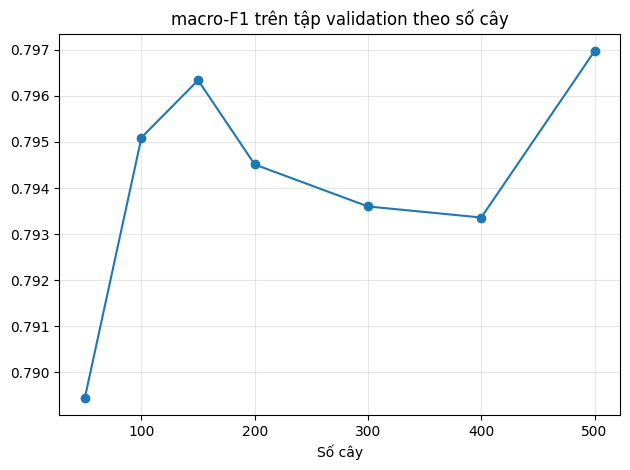

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score
import pandas as pd
import matplotlib.pyplot as plt

# warm_start giữ lại các cây đã có, nên mỗi vòng chỉ thêm cây chứ không huấn luyện lại từ đầu
val_model = RandomForestClassifier(
    **{**best_params, "warm_start": True}, n_jobs=-1, random_state=42
)

X_tr_v, y_tr_v = X[train_idx], y_enc[train_idx]
X_val, y_val = X[val_idx], y_enc[val_idx]

TREE_COUNTS = [50, 100, 150, 200, 300, 400, 500]
curve = []

for n in TREE_COUNTS:
    val_model.set_params(n_estimators=n)
    val_model.fit(X_tr_v, y_tr_v)

    pred = val_model.predict(X_val)
    row = {
        "n_estimators": n,
        "val_accuracy": accuracy_score(y_val, pred),
        "val_macro_F1": f1_score(y_val, pred, average="macro"),
        "val_balanced_acc": balanced_accuracy_score(y_val, pred),
    }
    curve.append(row)
    print("n=%3d | accuracy %6.2f%% | macro-F1 %.4f | balanced acc %.4f"
          % (n, row["val_accuracy"] * 100, row["val_macro_F1"], row["val_balanced_acc"]))

curve_df = pd.DataFrame(curve)
BEST_N_ESTIMATORS = int(curve_df.loc[curve_df["val_macro_F1"].idxmax(), "n_estimators"]
)
print("\nSố cây được chọn theo macro-F1 trên validation:", BEST_N_ESTIMATORS)

ax = curve_df.plot(x="n_estimators", y="val_macro_F1", marker="o", legend=False)
ax.set_title("macro-F1 trên tập validation theo số cây")
ax.set_xlabel("Số cây")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 6.5. Đánh giá cuối và lưu mô hình

Train lại trên **90% (train + validation)** với cấu hình và số cây đã chốt, rồi đánh giá **một lần duy nhất** trên tập test 10%. Tập test này chưa từng tham gia bất kỳ bước tìm tham số nào ở mục 6.3 và 6.5.

Báo cáo **cả hai con số**: mean ± std của 5-fold ở mục 6.3, và điểm trên test ở đây. Nếu hai số lệch xa nhau, nguyên nhân nhiều khả năng là mất cân bằng lớp — tập test vẫn có tỉ lệ lớp đông ảnh cao hơn trung bình, nên accuracy dễ đẹp hơn con số trung bình của CV.

Ô cuối cùng kiểm chứng giả thuyết "mất cân bằng là nguyên nhân recall thấp" bằng cách thử thêm `class_weight='balanced'`. Phép so sánh đó chạy trên **tập validation**, không phải tập test — để test vẫn chỉ được dùng đúng một lần.


In [ ]:
import json
import os
import pickle
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score, classification_report
from sklearn.preprocessing import LabelEncoder

# Train lại trên 90% (train + validation) — tập test chưa từng tham gia bước nào ở trên
final_model = RandomForestClassifier(
    **{**best_params, "n_estimators": BEST_N_ESTIMATORS},
    n_jobs=-1, random_state=42,
)
final_model.fit(X[cv_idx], y_enc[cv_idx])

y_test = y_enc[test_idx]
pred_test = final_model.predict(X[test_idx])

test_metrics = {
    "accuracy": accuracy_score(y_test, pred_test),
    "macro_F1": f1_score(y_test, pred_test, average="macro"),
    "weighted_F1": f1_score(y_test, pred_test, average="weighted"),
    "balanced_accuracy": balanced_accuracy_score(y_test, pred_test),
}

print("=== KẾT QUẢ TRÊN TẬP TEST 10% (chưa từng dùng để tìm tham số) ===")
for k, v in test_metrics.items():
    print("   %-20s %.4f" % (k, v))

print("\nSo sánh với 5-fold ở mục 6.3:")
print("   macro-F1 trung bình : %.4f ± %.4f"
      % (cv_results["mean_test_score"].iloc[0], cv_results["std_test_score"].iloc[0]))
print("   macro-F1 trên test  : %.4f" % test_metrics["macro_F1"])
print()

print(classification_report(y_test, pred_test, target_names=CLASSES, zero_division=0))

# Lưu lại kèm cấu hình để sau này biết mô hình được huấn luyện thế nào
os.makedirs(MODEL_DIR, exist_ok=True)

with open(MODEL_PATH, "wb") as f:
    pickle.dump(final_model, f, protocol=4)

le = LabelEncoder().fit(CLASSES)
with open(ENCODER_PATH, "wb") as f:
    pickle.dump(le, f, protocol=4)

with open(os.path.join(MODEL_DIR, "training_meta.json"), "w", encoding="utf-8") as f:
    json.dump({
        "params": dict(best_params),
        "n_estimators": BEST_N_ESTIMATORS,
        "hamming_threshold": HAMMING_THRESHOLD,
        "so_nhom": int(len(np.unique(groups))),
        "feature_count": int(X.shape[1]),
        "cv_macro_f1_mean": float(cv_results["mean_test_score"].iloc[0]),
        "cv_macro_f1_std": float(cv_results["std_test_score"].iloc[0]),
        "test_metrics": {k: float(v) for k, v in test_metrics.items()},
    }, f, ensure_ascii=False, indent=2)

print("Đã lưu mô hình, bộ giải nhãn và cấu hình vào:", MODEL_DIR)

=== KẾT QUẢ TRÊN TẬP TEST 10% (chưa từng dùng để tìm tham số) ===
   accuracy             0.8207
   macro_F1             0.7931
   weighted_F1          0.8216
   balanced_accuracy    0.8249

So sánh với 5-fold ở mục 6.3:
   macro-F1 trung bình : 0.7897 ± 0.0071
   macro-F1 trên test  : 0.7931

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.51      0.68      0.59        63
                                 Apple___Black_rot       0.93      0.87      0.90        63
                          Apple___Cedar_apple_rust       0.53      0.74      0.62        27
                                   Apple___healthy       0.68      0.61      0.64       164
                               Blueberry___healthy       0.79      0.84      0.82       148
          Cherry_(including_sour)___Powdery_mildew       0.75      0.88      0.81       105
                 Cherry_(including_sour)___healthy       0.6

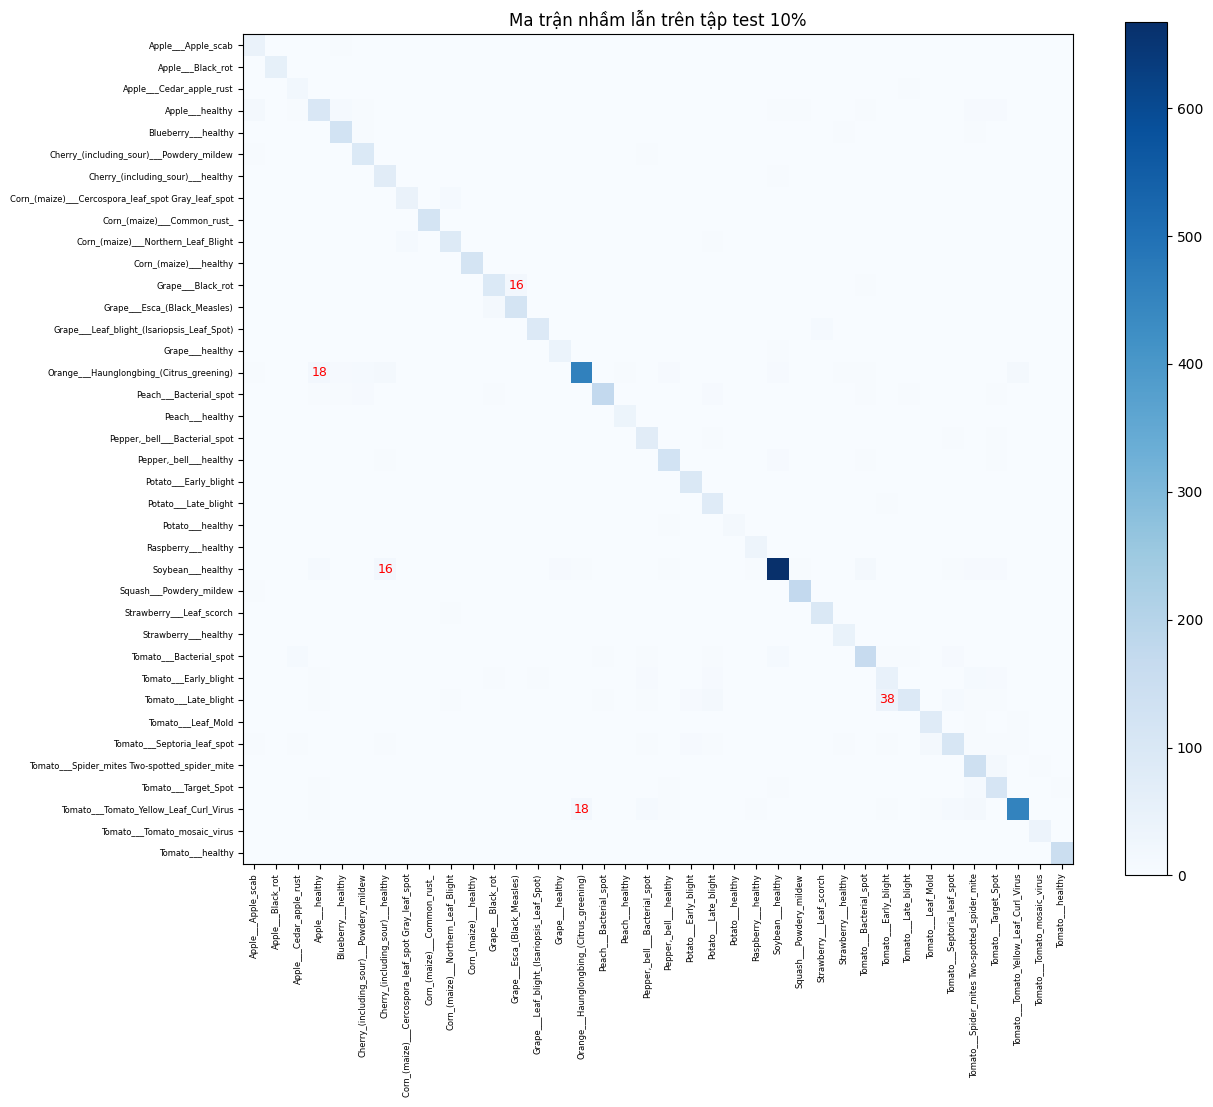

15 lớp có recall thấp nhất trên tập test:
                                                    so_anh_test  recall
Tomato___Early_blight                                        99  0.4747
Tomato___Late_blight                                        189  0.4762
Tomato___Septoria_leaf_spot                                 178  0.5899
Apple___healthy                                             164  0.6098
Apple___Apple_scab                                           63  0.6825
Potato___healthy                                             15  0.7333
Pepper,_bell___Bacterial_spot                               100  0.7400
Apple___Cedar_apple_rust                                     27  0.7407
Tomato___Bacterial_spot                                     216  0.7500
Peach___Bacterial_spot                                      229  0.7598
Grape___Black_rot                                           119  0.7731
Potato___Late_blight                                        101  0.7822
Tomato___Target_Spot  

In [ ]:
from sklearn.metrics import confusion_matrix, recall_score

cm = confusion_matrix(y_test, pred_test, labels=range(len(CLASSES)))

fig, ax = plt.subplots(figsize=(13, 11))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(CLASSES)))
ax.set_yticks(range(len(CLASSES)))
ax.set_xticklabels(CLASSES, rotation=90, fontsize=6)
ax.set_yticklabels(CLASSES, fontsize=6)
ax.set_title("Ma trận nhầm lẫn trên tập test 10%")
fig.colorbar(im, ax=ax)

# Chú thích năm cặp bị nhầm nặng nhất, bỏ qua đường chéo
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)
pairs = np.dstack(np.unravel_index(np.argsort(cm_off.ravel())[::-1][:5], cm_off.shape))[0]
for i, j in pairs:
    ax.text(j, i, int(cm[i, j]), ha="center", va="center",
            color="red" if cm[i, j] > cm_off.max() * 0.3 else "black", fontsize=9)

plt.tight_layout()
plt.show()

# Recall từng lớp, xếp theo thứ tự tăng dần để lớp yếu nằm trên cùng
per_class = pd.DataFrame({
    "so_anh_test": pd.Series(y[test_idx]).value_counts().reindex(CLASSES).fillna(0).astype(int),
    "recall": recall_score(y_test, pred_test, average=None,
                           labels=range(len(CLASSES)), zero_division=0),
}, index=CLASSES).sort_values("recall")

print("15 lớp có recall thấp nhất trên tập test:")
print(per_class.head(15).round(4).to_string())

In [ ]:
from sklearn.metrics import recall_score, f1_score, balanced_accuracy_score

# Empirically verify the hypothesis that imbalance is the cause of low recall.
# Compare on the validation set rather than the test set.
base_model = RandomForestClassifier(
    **{**best_params, "n_estimators": BEST_N_ESTIMATORS},
    n_jobs=-1, random_state=42,
)
base_model.fit(X_tr_v, y_tr_v)

cw_model = RandomForestClassifier(
    **{**best_params, "n_estimators": BEST_N_ESTIMATORS, "class_weight": "balanced"},
    n_jobs=-1, random_state=42,
)
cw_model.fit(X_tr_v, y_tr_v)

base_val = base_model.predict(X_val)
cw_val = cw_model.predict(X_val)

cw_df = pd.DataFrame({
    "recall": recall_score(y_val, base_val, average=None,
                           labels=range(len(CLASSES)), zero_division=0),
    "balanced_recall": recall_score(y_val, cw_val, average=None,
                                    labels=range(len(CLASSES)), zero_division=0),
}, index=CLASSES)
cw_df["difference"] = cw_df["balanced_recall"] - cw_df["recall"]
cw_df = cw_df.sort_values("difference", ascending=False)

print("On the 10% validation set:")
print("   unbalanced : macro-F1 %.4f | balanced acc %.4f"
      % (f1_score(y_val, base_val, average="macro"),
         balanced_accuracy_score(y_val, base_val)))
print("   balanced   : macro-F1 %.4f | balanced acc %.4f"
      % (f1_score(y_val, cw_val, average="macro"),
         balanced_accuracy_score(y_val, cw_val)))

print("\nTop 15 classes with the highest improvement when using class_weight='balanced':")
print(cw_df.head(15).round(4).to_string())

NameError: name 'RandomForestClassifier' is not defined

## 7. Tóm tắt

### Quy trình đã thực hiện

1. Cài đặt thư viện và tải bộ dữ liệu PlantVillage gồm 38 lớp bệnh.
2. Trích xuất 1.977 đặc trưng cho mỗi ảnh: histogram màu HSV và BGR, HOG, thống kê từng kênh, mật độ cạnh Canny.
3. Dò ảnh trùng lặp bằng perceptual hash và Union-Find, rồi gom thành các nhóm.
4. Chia tập theo nhóm ảnh, bố cục 80% train / 10% validation / 10% test.
5. Tìm siêu tham số bằng 5-fold cross-validation chấm theo macro-F1.
6. Dùng tập validation làm tín hiệu dừng với `warm_start`, rồi đánh giá một lần duy nhất trên tập test.

### Kết quả

Điền các con số lấy từ kết quả in ra ở mục 6.3 và 6.5:

- **5-fold**: macro-F1 = `... ± ...`.
- **Tập test 10%**: accuracy = `...%`, macro-F1 = `...`, balanced accuracy = `...`.
- **Cấu hình tốt nhất**: `...` cây, `max_depth = ...`, `class_weight = ...`.

### Nhận xét

Ưu điểm của cách làm này là đánh giá còn trung thực: ảnh gần trùng của cùng một chiếc lá không bao giờ nằm ở cả hai phía, tập test không tham gia tìm tham số, và kết quả đi kèm độ lệch thay vì một con số đơn.

Hạn chế còn lại:

- **Mất cân bằng lớp nghiêm trọng**: lớp nhiều nhất gấp 36 lần lớp ít nhất. Với các lớp chỉ vài trăm ảnh, mọi ước lượng về chúng đều nhiễu cao.
- **Các lớp bệnh quá giống nhau về hình ảnh**: ba bệnh của khoai tây và hai bệnh của cà chua có đặc điểm thị giác gần giống nhau, đây là nguồn nhầm lẫn chính.
- **Đặc trưng thủ công đã đến giới hạn**: HOG chiếm 89% số chiều nhưng vẫn là đặc trưng cố định, không học được.

### Hướng nâng cao

Bổ sung dữ liệu cho các lớp hiếm, thử `class_weight='balanced'` ở mục 6.5, hoặc chuyển sang mạng nơ-ron tích chập để tự học đặc trưng thay vì thiết kế tay.
